# CA3 input, BARR bursts onto CCK interneurons and CA1 criticality (d2) in the CA3–CA1 network model

Spiking network model, frozen synaptic weights during sleep, 180 s per run.

**CA3 input**: extra Poisson drive to every CA3 pyramidal cell (0–80 Hz). **BARR**: 300-ms bursts of 50-Hz input to every CCK cell, at 0–0.5 events/s.
**CCK time scale**: CCK→pyramidal-cell GABA decay as a multiple of the PV decay (3.3 ms); the original CA1net CCK is 2.2× PV. what is shown here is 6.6xPV, results are consistent amongst all the CCK decay scale >= 2.2× PV decay scale. 
**d2**: distance to criticality of the pooled CA1 activity (5-ms bins, AR order 20; 30-s blocks with detected CA3 replays ± 50 ms removed); lower = closer to criticality.
5 paired seeds (same network and noise across conditions within a seed). The seed is the statistical unit for every test on paired effects.

Data: `../data/figS5/figS5_runs.csv` (one row per run) and `../data/figS5/figS5_windows.csv` (one row per d2 window, panel b; CCK 6.6× PV, BARR off).

| panel | content | 
|---|---|
| a | d2 vs CA3 drive, BARR off | 
| b | d2 per window for 5-, 10- and 15-s windows, BARR off | 
| c | d2 vs BARR rate at CA3 drives 10, 20, 40 Hz | 
| d | paired BARR effect (Δd2 vs BARR off) at every CA3 drive | 
| e | landscape: d2 over CA3 drive × BARR rate (colour: CA1 MUA) | 
| f | paired BARR effect for CCK decay 1, 2, 8, 16 × PV (CA3 drives 10, 20, 40 Hz) | 
| g | slope of d2 vs BARR rate per CCK decay | 



In [1]:
import os
import warnings

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

DATA = '../data/figS5'
FIGDIR = '.'
FONTS = '../data/fonts'
for f in ['Regular', 'Bold']:   # Helvetica clone (Nimbus Sans), embedded as TrueType in the PDF; falls back to Helvetica/Arial
    if os.path.exists(f'{FONTS}/NimbusSans-{f}.ttf'):
        fm.fontManager.addfont(f'{FONTS}/NimbusSans-{f}.ttf')

runs = pd.read_csv(f'{DATA}/figS5_runs.csv')
wins = pd.read_csv(f'{DATA}/figS5_windows.csv')
DRIVES = sorted(runs.ca3_drive_hz.unique()); SHOW = [10.0, 20.0, 40.0]
TS = {'pv': 1, 't2': 2, 't8': 8, 't16': 16}                         # panels h, i: CCK decay as a multiple of PV
NAME = {'base': '22× PV (73 ms)', 'fast': '6.6× PV (22 ms)', 'native': '2.2× PV (7.3 ms, CA1net CCK)',
        'pv': '= PV (3.3 ms)', 't2': '2× PV (6.6 ms)', 't8': '8× PV (26 ms)', 't16': '16× PV (53 ms)'}
print(runs.groupby('variant').size().to_dict(), '| windows:', len(wins))
runs.head()

{'base': 180, 'fast': 180, 'native': 180, 'pv': 180, 't16': 180, 't2': 180, 't8': 180} | windows: 1890


,variant,cck_decay_x_pv,cck_decay_ms,ca3_drive_hz,barr_rate_hz,seed,d2,ca1_mua_hz,pv_rate_hz,cck_rate_hz
0,pv,1.0,3.3,0.0,0.0,0,0.023099,0.321297,25.570493,0.343816
1,pv,1.0,3.3,0.0,0.0,1,0.020736,0.327633,26.575994,0.352603
2,pv,1.0,3.3,0.0,0.0,2,0.023162,0.352910,28.670104,0.313956
3,pv,1.0,3.3,0.0,0.0,3,0.021801,0.358442,29.009946,0.348727
4,pv,1.0,3.3,0.0,0.0,4,0.021716,0.324427,26.075703,0.336815


## Statistics
- **CA3 drive (a):** Spearman ρ between CA3 drive and d2 over runs (BARR off; n = 6 drives × 5 seeds); Friedman test across drives with seeds as blocks.
- **Window length (b):** Spearman ρ with CA3 drive per window length (n = windows); Kruskal–Wallis across window lengths at each drive (medians); Levene test on drive-centred d2 across window lengths (spread).
- **BARR (c, d, f):** for each seed and CA3 drive, the slope of d2 vs BARR rate (least squares over the 6 rates). One-sided one-sample t-test of slope < 0 over seeds (n = 5), Holm-corrected over the drives (c, d) or CCK decays (f) tested. In c also the Spearman ρ of the paired change (vs BARR off, same seed and drive) with BARR rate.
- **Landscape (e):** BARR slope averaged over drives per seed (n = 5, one-sided t-test); Spearman ρ between CA3 drive and slope (n = 30 seed × drive).
- **CCK decay (g):** slopes per seed × drive (n = 15 per decay); Spearman ρ between decay and slope (n = 60); Kruskal–Wallis across the four decays.

In [2]:
def paired_change(d):
    # d2(BARR rate) - d2(BARR off), same variant, seed and CA3 drive
    ref = d[d.barr_rate_hz == 0].set_index(['variant', 'seed', 'ca3_drive_hz']).d2
    return d.assign(delta=d.d2.to_numpy() - ref.reindex(pd.MultiIndex.from_frame(d[['variant', 'seed', 'ca3_drive_hz']])).to_numpy())


def slopes(d):
    # slope of d2 vs BARR rate per (variant, seed, drive)
    return (d.groupby(['variant', 'seed', 'ca3_drive_hz'])
             .apply(lambda g: np.polyfit(g.barr_rate_hz, g.d2, 1)[0], include_groups=False).rename('slope').reset_index())


def t_less(v):
    return stats.ttest_1samp(np.asarray(v, float), 0, alternative='less').pvalue


def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); out = np.empty(len(p)); run = 0.0
    for k, i in enumerate(o):
        run = max(run, (len(p) - k) * p[i]); out[i] = min(run, 1.0)
    return out


def fp(p):
    return f'{p:.2g}' if p >= 1e-300 else '<1e-300'


ST = {}
# a, b: CA3 drive
for v in ('base', 'fast'):
    x = runs[(runs.variant == v) & (runs.barr_rate_hz == 0)]
    rho, p = stats.spearmanr(x.ca3_drive_hz, x.d2)
    fr = stats.friedmanchisquare(*[g.sort_values('seed').d2.to_numpy() for _, g in x.groupby('ca3_drive_hz')])
    ST['drive', v] = dict(rho=rho, p=p, n=len(x), chi2=fr.statistic, p_fried=fr.pvalue)
# c: window length
c = []
for L, g in wins.groupby('window_s'):
    rho, p = stats.spearmanr(g.ca3_drive_hz, g.d2); c.append(dict(L=L, n=len(g), rho=rho, p=p))
ST['wl'] = pd.DataFrame(c)
ST['wl_kw'] = [stats.kruskal(*[g.d2 for _, g in wins[wins.ca3_drive_hz == d].groupby('window_s')]).pvalue for d in DRIVES]
res = wins.d2 - wins.groupby(['window_s', 'ca3_drive_hz']).d2.transform('median')
ST['wl_lev'] = stats.levene(*[res[wins.window_s == L] for L in sorted(wins.window_s.unique())])
# d, e, f, g: BARR at each drive
SL = slopes(runs)
for v in ('base', 'fast'):
    y = paired_change(runs[(runs.variant == v) & runs.ca3_drive_hz.isin(SHOW)]); y = y[y.barr_rate_hz > 0]
    rho, p = stats.spearmanr(y.barr_rate_hz, y.delta)
    s = SL[SL.variant == v]
    ST['barr', v] = dict(rho=rho, p=p, n=len(y),
                         per_drive={d: (s[s.ca3_drive_hz == d].slope.mean(), s[s.ca3_drive_hz == d].slope.sem(), t_less(s[s.ca3_drive_hz == d].slope)) for d in DRIVES})
    for key, drv in (('show', SHOW), ('all', DRIVES)):
        ST['barr', v]['holm_' + key] = dict(zip(drv, holm([ST['barr', v]['per_drive'][d][2] for d in drv])))
    seed_sl = s.groupby('seed').slope.mean(); r2, p2 = stats.spearmanr(s.ca3_drive_hz, s.slope)
    ST['land', v] = dict(mean=seed_sl.mean(), sem=seed_sl.sem(), p=t_less(seed_sl), rho=r2, p_rho=p2, n=len(s))
# h, i: CCK decay (CA3 drives 10, 20, 40 Hz)
s5 = SL[SL.variant.isin(TS) & SL.ca3_drive_hz.isin(SHOW)]
per_seed = s5.groupby(['variant', 'seed']).slope.mean()
ph = holm([t_less(per_seed.loc[v]) for v in TS])
ST['ts'] = {v: (per_seed.loc[v].mean(), per_seed.loc[v].sem(), p_) for v, p_ in zip(TS, ph)}
rho, p = stats.spearmanr(s5.variant.map(TS), s5.slope); kw = stats.kruskal(*[g.slope for _, g in s5.groupby('variant')])
ST['ts_trend'] = dict(rho=rho, p=p, n=len(s5), H=kw.statistic, p_kw=kw.pvalue)

summary = pd.DataFrame([
    {'panel': 'a', 'test': 'Spearman d2 ~ CA3 drive (22× PV)', 'stat': ST['drive', 'base']['rho'], 'p': ST['drive', 'base']['p'], 'n': ST['drive', 'base']['n']},
    {'panel': 'a', 'test': 'Friedman across drives (seeds as blocks)', 'stat': ST['drive', 'base']['chi2'], 'p': ST['drive', 'base']['p_fried'], 'n': 5},
    {'panel': 'b', 'test': 'Spearman d2 ~ CA3 drive (6.6× PV)', 'stat': ST['drive', 'fast']['rho'], 'p': ST['drive', 'fast']['p'], 'n': ST['drive', 'fast']['n']},
    {'panel': 'b', 'test': 'Friedman across drives (seeds as blocks)', 'stat': ST['drive', 'fast']['chi2'], 'p': ST['drive', 'fast']['p_fried'], 'n': 5},
    *[{'panel': 'c', 'test': f'Spearman d2 ~ CA3 drive, {r.L:g}-s windows', 'stat': r.rho, 'p': r.p, 'n': r.n} for r in ST['wl'].itertuples()],
    {'panel': 'c', 'test': 'Kruskal–Wallis across window lengths (max p over drives)', 'stat': np.nan, 'p': max(ST['wl_kw']), 'n': len(DRIVES)},
    {'panel': 'c', 'test': 'Levene, drive-centred d2 across window lengths', 'stat': ST['wl_lev'].statistic, 'p': ST['wl_lev'].pvalue, 'n': len(wins)},
    *[{'panel': p_, 'test': f'Spearman paired Δd2 ~ BARR rate, CA3 10–40 Hz ({NAME[v]})', 'stat': ST['barr', v]['rho'], 'p': ST['barr', v]['p'], 'n': ST['barr', v]['n']} for p_, v in (('d', 'base'), ('e', 'fast'))],
    *[{'panel': p_, 'test': f'BARR slope < 0 at CA3 {d:g} Hz ({NAME[v]}), Holm over {"3" if p_ != "f" else "6"} drives',
       'stat': ST['barr', v]['per_drive'][d][0], 'p': ST['barr', v]['holm_' + ('all' if p_ == 'f' else 'show')][d], 'n': 5}
      for p_, v, drv in (('d', 'base', SHOW), ('e', 'fast', SHOW), ('f', 'fast', DRIVES)) for d in drv],
    {'panel': 'g', 'test': 'BARR slope < 0, mean over drives (6.6× PV)', 'stat': ST['land', 'fast']['mean'], 'p': ST['land', 'fast']['p'], 'n': 5},
    {'panel': 'g', 'test': 'Spearman BARR slope ~ CA3 drive (6.6× PV)', 'stat': ST['land', 'fast']['rho'], 'p': ST['land', 'fast']['p_rho'], 'n': ST['land', 'fast']['n']},
    *[{'panel': 'h', 'test': f'BARR slope < 0, CCK decay {NAME[v]}, Holm over 4', 'stat': ST['ts'][v][0], 'p': ST['ts'][v][2], 'n': 5} for v in TS],
    {'panel': 'i', 'test': 'Spearman slope ~ CCK decay (1, 2, 8, 16 × PV)', 'stat': ST['ts_trend']['rho'], 'p': ST['ts_trend']['p'], 'n': ST['ts_trend']['n']},
    {'panel': 'i', 'test': 'Kruskal–Wallis across CCK decays', 'stat': ST['ts_trend']['H'], 'p': ST['ts_trend']['p_kw'], 'n': ST['ts_trend']['n']},
])
summary = summary[~summary.panel.isin(['a', 'd'])]   # the 22× PV panels (old a, d) moved to Fig. 3 c, d
summary['panel'] = summary.panel.map({'b': 'a', 'c': 'b', 'e': 'c', 'f': 'd', 'g': 'e', 'h': 'f', 'i': 'g'})
summary.to_csv(f'{FIGDIR}/figS5_statistics.csv', index=False)
# pd.set_option('display.width', 200); summary.style.format({'stat': '{:.4g}', 'p': '{:.3g}'})

## Figure
Thin grey lines: individual seeds; dots and bars: mean ± s.e.m. over the 5 seeds. Panel titles: the test of that panel (bold and *, p < 0.05). Full statistics: `figS5_statistics.csv`.

In [3]:
RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans', 'Nimbus Sans TT', 'Arial'], 'font.size': 7,
      'axes.linewidth': 1, 'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5,
      'ytick.major.size': 2.5, 'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False}
BLACK, GREY, MUTED = '#1f1f1d', '#b4b2a9', '#8a887f'
VCOL = {'base': '#0f5aa3', 'fast': '#3585bf', 'native': '#66abd4', 'pv': '#a6cee4', 't2': '#66abd4', 't8': '#2f7fbf', 't16': '#08306b'}
LCOL = {5: '#9ecae1', 10: '#4292c6', 15: '#08306b'}
CM = plt.get_cmap('cool'); DN = Normalize(0, len(DRIVES) - 1); DCOL = {d: CM(DN(k)) for k, d in enumerate(DRIVES)}
POS = {d: k for k, d in enumerate(DRIVES)}


def title(ax, text, p):
    sig = p < 0.05
    ax.set_title(text + (' *' if sig else ''), fontsize=5.6, pad=2, linespacing=1.15,
                 fontweight='bold' if sig else 'normal', color=BLACK if sig else MUTED)


def letter(ax, l, dx=-0.42, dy=1.12, transform=None):
    (ax.text2D if hasattr(ax, 'text2D') else ax.text)(dx, dy, l, transform=transform or ax.transAxes, fontsize=9, fontweight='bold', va='bottom')


def mean_sem_line(ax, x, g, **kw):
    m, e = g.mean(), g.sem()
    ax.errorbar(x, m.values, e.values, marker='o', ms=2.5, capsize=1.5, lw=1, **kw)


def finish(ax, l):
    ax.tick_params(labelsize=5.5, pad=1.5)
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
    letter(ax, l)

### a: d2 vs CA3 drive (CCK 6.6× PV, BARR off)

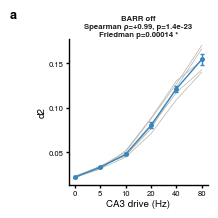

In [4]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9))
    x = runs[(runs.variant == 'fast') & (runs.barr_rate_hz == 0)]
    for s, g in x.groupby('seed'):
        g = g.sort_values('ca3_drive_hz'); ax.plot([POS[d] for d in g.ca3_drive_hz], g.d2, color=GREY, lw=0.5, zorder=1)
    mean_sem_line(ax, [POS[d] for d in DRIVES], x.groupby('ca3_drive_hz').d2, color=VCOL['fast'], zorder=3)
    ax.set_xticks(range(len(DRIVES))); ax.set_xticklabels([f'{d:g}' for d in DRIVES]); ax.set_xlabel('CA3 drive (Hz)', labelpad=1); ax.set_ylabel('d2', labelpad=1)
    st = ST['drive', 'fast']
    title(ax, f"BARR off\nSpearman ρ={st['rho']:+.2f}, p={fp(st['p'])}\nFriedman p={fp(st['p_fried'])}", st['p'])
    finish(ax, 'a')
    fig.savefig(f'{FIGDIR}/figS5_a.pdf', bbox_inches='tight')
    plt.show()

### b: d2 per window, 5-, 10-, 15-s windows (CCK 6.6× PV, BARR off)

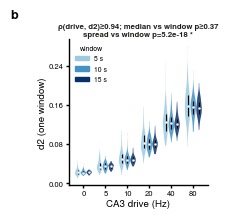

In [5]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9)); w = 0.26
    for k, L in enumerate(sorted(wins.window_s.unique())):
        pos = np.arange(len(DRIVES)) + (k - 1) * w
        data = [wins[(wins.window_s == L) & (wins.ca3_drive_hz == d)].d2.dropna().to_numpy() for d in DRIVES]
        vp = ax.violinplot(data, positions=pos, widths=w * 0.95, showextrema=False)
        for b in vp['bodies']: b.set_facecolor(LCOL[L]); b.set_edgecolor('none'); b.set_alpha(0.85)
        q1, med, q3 = np.array([np.percentile(v_, [25, 50, 75]) for v_ in data]).T
        ax.vlines(pos, q1, q3, color='k', lw=0.8); ax.scatter(pos, med, s=3, color='w', zorder=3, lw=0)
    ax.set_xticks(range(len(DRIVES))); ax.set_xticklabels([f'{d:g}' for d in DRIVES]); ax.set_xlabel('CA3 drive (Hz)', labelpad=1); ax.set_ylabel('d2 (one window)', labelpad=1)
    ax.legend(handles=[Patch(color=LCOL[L], label=f'{L:g} s') for L in LCOL], fontsize=5, loc='upper left', title='window', title_fontsize=5)
    title(ax, f"ρ(drive, d2)≥{ST['wl'].rho.min():.2f}; median vs window p≥{min(ST['wl_kw']):.2f}\nspread vs window p={fp(ST['wl_lev'].pvalue)}", ST['wl_lev'].pvalue)
    finish(ax, 'b')
    fig.savefig(f'{FIGDIR}/figS5_b.pdf', bbox_inches='tight')
    plt.show()

### c: d2 vs BARR rate at CA3 10, 20, 40 Hz (CCK 6.6× PV)

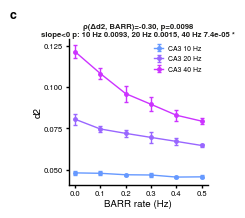

In [6]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9))
    x = runs[(runs.variant == 'fast') & runs.ca3_drive_hz.isin(SHOW)]
    for d in SHOW:
        mean_sem_line(ax, sorted(x.barr_rate_hz.unique()), x[x.ca3_drive_hz == d].groupby('barr_rate_hz').d2, color=DCOL[d], label=f'CA3 {d:g} Hz')
    ax.set_xlabel('BARR rate (Hz)', labelpad=1); ax.set_ylabel('d2', labelpad=1); ax.legend(fontsize=5, loc='upper right', handlelength=1.2)
    st = ST['barr', 'fast']; ps = st['holm_show']
    title(ax, f"ρ(Δd2, BARR)={st['rho']:+.2f}, p={fp(st['p'])}\nslope<0 p: " + ', '.join(f"{d:g} Hz {fp(ps[d])}" for d in SHOW), st['p'])
    finish(ax, 'c')
    fig.savefig(f'{FIGDIR}/figS5_c.pdf', bbox_inches='tight')
    plt.show()

### d: paired BARR effect at every CA3 drive (CCK 6.6× PV)

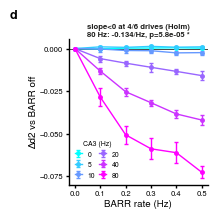

In [7]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9)); y = paired_change(runs[runs.variant == 'fast'])
    for d in DRIVES:
        mean_sem_line(ax, sorted(y.barr_rate_hz.unique()), y[y.ca3_drive_hz == d].groupby('barr_rate_hz').delta, color=DCOL[d], label=f'{d:g}')
    ax.axhline(0, color='k', lw=0.5); ax.set_xlabel('BARR rate (Hz)', labelpad=1); ax.set_ylabel('Δd2 vs BARR off', labelpad=1)
    ax.legend(title='CA3 (Hz)', fontsize=5, title_fontsize=5, ncol=2, loc='lower left', handlelength=1, columnspacing=0.6)
    st = ST['barr', 'fast']; ps = st['holm_all']; ns = sum(ps[d] < 0.05 for d in DRIVES)
    title(ax, f"slope<0 at {ns}/6 drives (Holm)\n80 Hz: {st['per_drive'][80.0][0]:.3f}/Hz, p={fp(ps[80.0])}", min(ps.values()))
    finish(ax, 'd')
    fig.savefig(f'{FIGDIR}/figS5_d.pdf', bbox_inches='tight')
    plt.show()

### e: landscape, d2 over CA3 drive × BARR rate (colour: CA1 MUA)

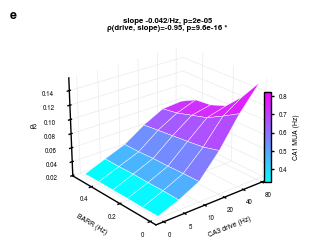

In [8]:
with plt.rc_context(RC):
    fig = plt.figure(figsize=(3.2, 2.6)); ax = fig.add_subplot(projection='3d')
    rv = runs[runs.variant == 'fast']; barrs = sorted(rv.barr_rate_hz.unique())
    Zd = rv.pivot_table(index='barr_rate_hz', columns='ca3_drive_hz', values='d2').reindex(index=barrs, columns=DRIVES).values
    Zm = rv.pivot_table(index='barr_rate_hz', columns='ca3_drive_hz', values='ca1_mua_hz').reindex(index=barrs, columns=DRIVES).values
    X, Y = np.meshgrid(np.arange(len(DRIVES)), barrs); mn = Normalize(np.nanmin(Zm), np.nanmax(Zm))
    ax.plot_surface(X, Y, Zd, facecolors=CM(mn(Zm)), edgecolor='w', lw=0.3, shade=False, rstride=1, cstride=1)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1, 1, 1, 0)); axis.pane.set_edgecolor('#bbbbbb'); axis._axinfo['grid'].update(color='#e6e6e6', linewidth=0.4)
    ax.set_xticks(range(len(DRIVES))); ax.set_xticklabels([f'{d:g}' for d in DRIVES], fontsize=4.5); ax.set_yticks(barrs[::2]); ax.set_yticklabels([f'{b:g}' for b in barrs[::2]], fontsize=4.5)
    ax.tick_params(axis='z', labelsize=4.5, pad=0); ax.tick_params(axis='x', pad=-3); ax.tick_params(axis='y', pad=-3)
    ax.set_xlabel('CA3 drive (Hz)', fontsize=5, labelpad=-8); ax.set_ylabel('BARR (Hz)', fontsize=5, labelpad=-8); ax.set_zlabel('d2', fontsize=5, labelpad=-7)
    ax.view_init(elev=24, azim=-130); ax.set_box_aspect((1.1, 1.0, 0.8), zoom=1.1)
    cax = ax.inset_axes([0.98, 0.25, 0.035, 0.45]); cb = fig.colorbar(plt.cm.ScalarMappable(cmap=CM, norm=mn), cax=cax)
    cb.set_label('CA1 MUA (Hz)', fontsize=5); cb.ax.tick_params(labelsize=4.5)
    st = ST['land', 'fast']
    ax.set_title(f"slope {st['mean']:.3f}/Hz, p={fp(st['p'])}\nρ(drive, slope)={st['rho']:+.2f}, p={fp(st['p_rho'])}"
                 + (' *' if st['p'] < 0.05 else ''), fontsize=5.6, pad=0, linespacing=1.15, fontweight='bold' if st['p'] < 0.05 else 'normal')
    fig.text(0.02, 0.92, 'e', fontsize=9, fontweight='bold', va='bottom')
    fig.savefig(f'{FIGDIR}/figS5_e.pdf', bbox_inches='tight')
    plt.show()

### f: paired BARR effect per CCK decay (CA3 10–40 Hz)

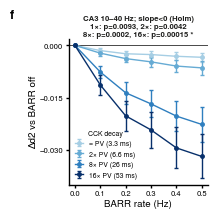

In [9]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9)); y = paired_change(runs[runs.variant.isin(TS) & runs.ca3_drive_hz.isin(SHOW)])
    for v in TS:
        mean_sem_line(ax, sorted(y.barr_rate_hz.unique()), y[y.variant == v].groupby('barr_rate_hz').delta, color=VCOL[v], label=NAME[v])
    ax.axhline(0, color='k', lw=0.5); ax.set_xlabel('BARR rate (Hz)', labelpad=1); ax.set_ylabel('Δd2 vs BARR off', labelpad=1)
    ax.legend(title='CCK decay', fontsize=5, title_fontsize=5, loc='lower left', handlelength=1.2)
    title(ax, 'CA3 10–40 Hz; slope<0 (Holm)\n' + ', '.join(f"{TS[v]}×: p={fp(ST['ts'][v][2])}" for v in list(TS)[:2]) + '\n' + ', '.join(f"{TS[v]}×: p={fp(ST['ts'][v][2])}" for v in list(TS)[2:]), max(ST['ts'][v][2] for v in TS))
    finish(ax, 'f')
    fig.savefig(f'{FIGDIR}/figS5_f.pdf', bbox_inches='tight')
    plt.show()

### g: BARR slope per CCK decay

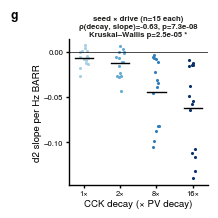

In [10]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(1.8, 1.9))
    for k, v in enumerate(TS):
        s_ = s5[s5.variant == v].slope
        ax.scatter(np.full(len(s_), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(s_)), s_, s=5, color=VCOL[v], lw=0, zorder=2)
        ax.plot([k - 0.25, k + 0.25], [s_.mean()] * 2, color='k', lw=1, zorder=3)
    ax.axhline(0, color='k', lw=0.5); ax.set_xticks(range(len(TS))); ax.set_xticklabels([f'{TS[v]}×' for v in TS])
    ax.set_xlabel('CCK decay (× PV decay)', labelpad=1); ax.set_ylabel('d2 slope per Hz BARR', labelpad=1)
    st = ST['ts_trend']; title(ax, f"seed × drive (n=15 each)\nρ(decay, slope)={st['rho']:+.2f}, p={fp(st['p'])}\nKruskal–Wallis p={fp(st['p_kw'])}", st['p'])
    finish(ax, 'g')
    fig.savefig(f'{FIGDIR}/figS5_g.pdf', bbox_inches='tight')
    plt.show()